# Problem 1: Comparison of Linear and Non-Linear Support Vector Machines (SVM)

## Executive Summary & Theoretical Foundations
The **Support Vector Machine (SVM)** is a foundational maximum-margin supervised learning paradigm established on Vapnik-Chervonenkis (VC) statistical learning theory. The primary objective is to discover a separating hyperplane that maximizes the geometric distance (margin) to the closest training exemplars (**support vectors**), thereby minimizing structural risk rather than empirical risk.

### 1. Mathematical Formulation

#### Primal Hard-Margin Formulation
For a linearly separable binary dataset $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^N$ with $\mathbf{x}_i \in \mathbb{R}^D$ and $y_i \in \{-1, +1\}$, the maximum-margin hyperplane is defined by:

$$\min_{\mathbf{w}, b} \frac{1}{2} \|\mathbf{w}\|^2 \quad \text{subject to} \quad y_i (\mathbf{w}^T \mathbf{x}_i + b) \ge 1, \quad \forall i=1, \dots, N$$

The geometric margin between the two parallel bounding hyperplanes $\mathbf{w}^T \mathbf{x} + b = \pm 1$ is $\gamma = \frac{2}{\|\mathbf{w}\|}$. Minimizing $\frac{1}{2}\|\mathbf{w}\|^2$ maximizes this separation margin.

#### Primal Soft-Margin Formulation (C-Regularization)
Real-world data is rarely strictly linearly separable. Introducing non-negative slack variables $\xi_i \ge 0$ allows controlled margin violations:

$$\min_{\mathbf{w}, b, \boldsymbol{\xi}} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^N \xi_i \quad \text{subject to} \quad y_i (\mathbf{w}^T \mathbf{x}_i + b) \ge 1 - \xi_i, \quad \xi_i \ge 0, \quad \forall i$$

where $C > 0$ governs the bias-variance trade-off:
- **Large $C$**: Heavy penalty on slack violations $\xi_i$, yielding narrower margins and potential overfitting (approaching hard margin).
- **Small $C$**: Tolerates margin violations, yielding wider margins and potential underfitting (higher regularization).

#### Dual Lagrangian Formulation & Support Vectors
Applying Karush-Kuhn-Tucker (KKT) conditions yields the dual optimization problem:

$$\max_{\boldsymbol{\alpha}} \sum_{i=1}^N \alpha_i - \frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N \alpha_i \alpha_j y_i y_j K(\mathbf{x}_i, \mathbf{x}_j) \quad \text{subject to} \quad 0 \le \alpha_i \le C, \quad \sum_{i=1}^N \alpha_i y_i = 0$$

Training instances with $\alpha_i > 0$ are the **Support Vectors**:
- If $0 < \alpha_i < C$, $\mathbf{x}_i$ lies precisely on the margin boundary ($y_i f(\mathbf{x}_i) = 1$, $\xi_i = 0$).
- If $\alpha_i = C$, $\mathbf{x}_i$ is a margin-violating point ($y_i f(\mathbf{x}_i) < 1$, $\xi_i > 0$).
- If $\alpha_i = 0$, $\mathbf{x}_i$ lies outside the margin boundary and has zero influence on the decision boundary (**Sparsity Property**).

The resulting decision function is:

$$f(\mathbf{x}) = \text{sign}\left( \sum_{i \in \text{SV}} \alpha_i y_i K(\mathbf{x}_i, \mathbf{x}) + b \right)$$

### 2. The Kernel Trick & Mercer Kernels
When data is non-linearly separable in input space $\mathcal{X}$, the **Kernel Trick** implicitly maps input vectors into a higher- (or infinite-) dimensional Hilbert feature space $\mathcal{H}$ via $\Phi: \mathcal{X} \to \mathcal{H}$ without explicitly evaluating $\Phi(\mathbf{x})$:

$$K(\mathbf{x}, \mathbf{x}') = \langle \Phi(\mathbf{x}), \Phi(\mathbf{x}') \rangle_\mathcal{H}$$

We evaluate four primary kernel functions in this notebook:
1. **Linear Kernel**:
$$K(\mathbf{x}, \mathbf{x}') = \mathbf{x}^T \mathbf{x}'$$
2. **Radial Basis Function (RBF / Gaussian) Kernel**:
$$K(\mathbf{x}, \mathbf{x}') = \exp\left( -\gamma \|\mathbf{x} - \mathbf{x}'\|^2 \right), \quad \gamma > 0$$
   Maps data to an infinite-dimensional RKHS; acts as a universal function approximator.
3. **Polynomial Kernel**:
$$K(\mathbf{x}, \mathbf{x}') = \left( \gamma \mathbf{x}^T \mathbf{x}' + r \right)^d, \quad d = 3$$
   Models feature cross-products up to degree $d$.
4. **Sigmoid (Hyperbolic Tangent) Kernel**:
$$K(\mathbf{x}, \mathbf{x}') = \tanh\left( \gamma \mathbf{x}^T \mathbf{x}' + r \right)$$
   Derives from multi-layer perceptron neural networks; conditional Mercer kernel (positive semi-definite only under restricted parameters).

---

### Notebook Architecture & Tasks
- **Task a**: Synthetic 2D dataset generation (`make_classification`, $N=500$) and real-world benchmark preparation (Iris Versicolor vs. Virginica, $N=100$) with stratified 70/30 split and `StandardScaler` normalization.
- **Task b**: Train 4 SVM architectures (`LinearSVC`, RBF, Polynomial degree 3, Sigmoid).
- **Task c**: Comparative quantitative evaluation (Accuracy, F1, Support Vectors count, fit runtime) and comprehensive 2D decision boundary visualization.
- **Task d**: In-depth theoretical kernel analysis, Mercer condition discussion, and scenario-based production selection guidelines.

In [4]:
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from sklearn.datasets import make_classification, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

# Deterministic seed for reproducible evaluation
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Matplotlib styling for high-clarity academic visualizations
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

print("SVM Evaluation Environment successfully initialized.")


SVM Evaluation Environment successfully initialized.


## 1. Data Generation, Preparation, and Standardization (Task a)

To rigorously evaluate linear and non-linear SVMs, we construct two complementary experimental testbeds:
1. **Synthetic 2D Classification Dataset (`make_classification`)**:
   - $N = 500$ samples, 2 informative features, 0 redundant features, 2 classes.
   - Non-linear separation landscape with cluster variance, presenting a challenging soft-margin boundary.
2. **Real-World Benchmark Dataset (Iris Dataset Binary Formulation)**:
   - Extracted from Fisher's canonical Iris dataset: **Versicolor** (Class 1) vs. **Virginica** (Class 2), mapped to binary labels $y \in \{0, 1\}$.
   - Evaluated on the two most discriminative morphological attributes: **Petal Length** and **Petal Width** ($N = 100$ samples).
   - Demonstrates real-world overlapping class distributions where non-linear boundaries are critical.

### Preprocessing Protocol:
- **Stratified Partitioning**: 70% Training ($N_{tr}$), 30% Testing ($N_{te}$) using `train_test_split(test_size=0.3, random_state=42, stratify=y)`.
- **Feature Scaling**: Z-score standardization via `StandardScaler()`:
$$x_{\text{scaled}} = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$
  Fitted strictly on training partitions to prevent data leakage.

In [5]:
# 1. Generate 2D Synthetic Dataset
X_syn, y_syn = make_classification(
    n_samples=500,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.0,
    random_state=RANDOM_SEED
)

# 2. Prepare Real-World Iris Dataset (Versicolor vs. Virginica)
iris = load_iris()
iris_mask = iris.target != 0  # Discard Setosa to retain non-trivial overlapping classes
X_iris = iris.data[iris_mask][:, [2, 3]]  # Petal Length, Petal Width
y_iris = iris.target[iris_mask] - 1      # Map to binary {0: Versicolor, 1: Virginica}

# 3. Stratified 70/30 Train/Test Partitioning
X_syn_tr, X_syn_te, y_syn_tr, y_syn_te = train_test_split(
    X_syn, y_syn, test_size=0.30, random_state=RANDOM_SEED, stratify=y_syn
)
X_iris_tr, X_iris_te, y_iris_tr, y_iris_te = train_test_split(
    X_iris, y_iris, test_size=0.30, random_state=RANDOM_SEED, stratify=y_iris
)

# 4. Standardize Features using StandardScaler (Zero Leakage Protocol)
scaler_syn = StandardScaler()
X_syn_tr_scaled = scaler_syn.fit_transform(X_syn_tr)
X_syn_te_scaled = scaler_syn.transform(X_syn_te)

scaler_iris = StandardScaler()
X_iris_tr_scaled = scaler_iris.fit_transform(X_iris_tr)
X_iris_te_scaled = scaler_iris.transform(X_iris_te)

print("="*75)
print("DATASET PREPARATION AND STRATIFIED PARTITION SUMMARY:")
print("="*75)
print(f"Synthetic Dataset: Total N={len(X_syn)} | Train N={len(X_syn_tr)} | Test N={len(X_syn_te)}")
print(f"  Class 0 (Train/Test): {np.sum(y_syn_tr==0)} / {np.sum(y_syn_te==0)} | Class 1: {np.sum(y_syn_tr==1)} / {np.sum(y_syn_te==1)}")
print(f"Iris Dataset:      Total N={len(X_iris)} | Train N={len(X_iris_tr)} | Test N={len(X_iris_te)}")
print(f"  Versicolor (Train/Test): {np.sum(y_iris_tr==0)} / {np.sum(y_iris_te==0)} | Virginica: {np.sum(y_iris_tr==1)} / {np.sum(y_iris_te==1)}")
print(f"  Feature Dimensions: 2D [{iris.feature_names[2]} vs. {iris.feature_names[3]}]")

DATASET PREPARATION AND STRATIFIED PARTITION SUMMARY:
Synthetic Dataset: Total N=500 | Train N=350 | Test N=150
  Class 0 (Train/Test): 174 / 75 | Class 1: 176 / 75
Iris Dataset:      Total N=100 | Train N=70 | Test N=30
  Versicolor (Train/Test): 35 / 15 | Virginica: 35 / 15
  Feature Dimensions: 2D [petal length (cm) vs. petal width (cm)]


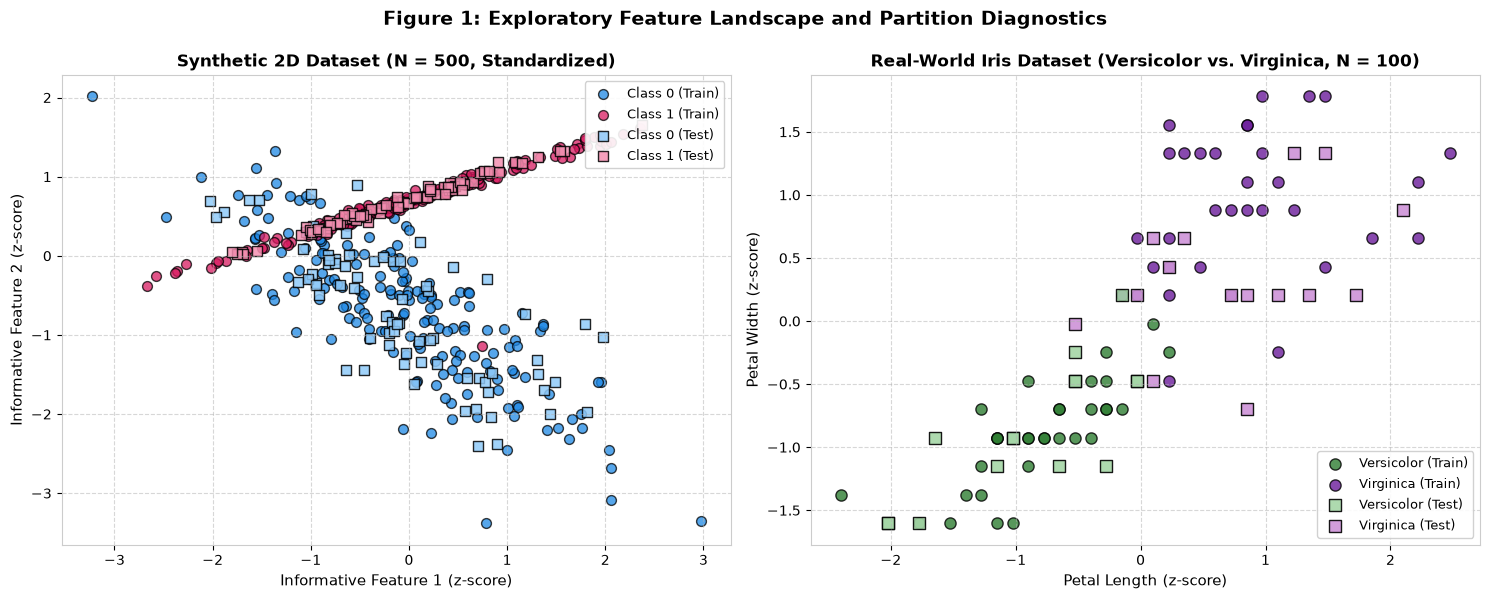

In [6]:
# Figure 1: Exploratory Feature Landscape and Partition Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=100)

# Panel 1: Synthetic Dataset
ax1 = axes[0]
ax1.scatter(X_syn_tr_scaled[y_syn_tr == 0, 0], X_syn_tr_scaled[y_syn_tr == 0, 1],
            color='#1E88E5', edgecolors='k', s=50, alpha=0.75, label='Class 0 (Train)')
ax1.scatter(X_syn_tr_scaled[y_syn_tr == 1, 0], X_syn_tr_scaled[y_syn_tr == 1, 1],
            color='#D81B60', edgecolors='k', s=50, alpha=0.75, label='Class 1 (Train)')
ax1.scatter(X_syn_te_scaled[y_syn_te == 0, 0], X_syn_te_scaled[y_syn_te == 0, 1],
            color='#90CAF9', edgecolors='k', marker='s', s=60, alpha=0.85, label='Class 0 (Test)')
ax1.scatter(X_syn_te_scaled[y_syn_te == 1, 0], X_syn_te_scaled[y_syn_te == 1, 1],
            color='#F48FB1', edgecolors='k', marker='s', s=60, alpha=0.85, label='Class 1 (Test)')
ax1.set_title('Synthetic 2D Dataset (N = 500, Standardized)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Informative Feature 1 (z-score)', fontsize=11)
ax1.set_ylabel('Informative Feature 2 (z-score)', fontsize=11)
ax1.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel 2: Iris Binary Dataset
ax2 = axes[1]
ax2.scatter(X_iris_tr_scaled[y_iris_tr == 0, 0], X_iris_tr_scaled[y_iris_tr == 0, 1],
            color='#2E7D32', edgecolors='k', s=65, alpha=0.8, label='Versicolor (Train)')
ax2.scatter(X_iris_tr_scaled[y_iris_tr == 1, 0], X_iris_tr_scaled[y_iris_tr == 1, 1],
            color='#6A1B9A', edgecolors='k', s=65, alpha=0.8, label='Virginica (Train)')
ax2.scatter(X_iris_te_scaled[y_iris_te == 0, 0], X_iris_te_scaled[y_iris_te == 0, 1],
            color='#A5D6A7', edgecolors='k', marker='s', s=75, alpha=0.9, label='Versicolor (Test)')
ax2.scatter(X_iris_te_scaled[y_iris_te == 1, 0], X_iris_te_scaled[y_iris_te == 1, 1],
            color='#CE93D8', edgecolors='k', marker='s', s=75, alpha=0.9, label='Virginica (Test)')
ax2.set_title('Real-World Iris Dataset (Versicolor vs. Virginica, N = 100)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Petal Length (z-score)', fontsize=11)
ax2.set_ylabel('Petal Width (z-score)', fontsize=11)
ax2.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Figure 1: Exploratory Feature Landscape and Partition Diagnostics', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

## 2. SVM Model Training and Decision Boundary Analysis on Synthetic Data (Tasks b & c)

We instantiate and benchmark the four required SVM configurations on the standardized synthetic dataset:
1. **Linear SVM (`LinearSVC`)**:
   - Implemented via `LinearSVC(random_state=42, max_iter=10000)`. Solves the primal problem via coordinate descent (LIBLINEAR).
   - In addition, we validate with `SVC(kernel='linear')` to extract exact dual coefficients $\alpha_i$ and explicit support vector coordinates.
2. **SVM with RBF Kernel (`SVC(kernel='rbf')`)**:
   - Default Gaussian kernel width $\gamma = 1 / (D \cdot \sigma^2_X) = \text{'scale'}$, $C = 1.0$.
3. **SVM with Polynomial Kernel (`SVC(kernel='poly', degree=3)`)**:
   - Cubic polynomial kernel with $d = 3, \gamma = \text{'scale'}, r = 0, C = 1.0$.
4. **SVM with Sigmoid Kernel (`SVC(kernel='sigmoid')`)**:
   - Hyperbolic tangent kernel with $\gamma = \text{'scale'}, r = 0, C = 1.0$.

### Support Vector Identification Protocol:
- For `SVC` models (RBF, Poly, Sigmoid, Linear), support vectors are extracted directly via `support_vectors_` and `n_support_`.
- For `LinearSVC`, support vectors correspond to training samples satisfying the KKT functional margin condition $y_i (\mathbf{w}^T \mathbf{x}_i + b) \le 1 + \epsilon$, indicating active constraints and margin violations.

In [7]:
# Train and benchmark all SVM models on the Synthetic Dataset
models_syn = {
    "Linear SVM (LinearSVC)": LinearSVC(random_state=RANDOM_SEED, max_iter=10000),
    "Linear SVM (SVC linear)": SVC(kernel='linear', random_state=RANDOM_SEED),
    "RBF SVM (SVC rbf)": SVC(kernel='rbf', random_state=RANDOM_SEED),
    "Poly SVM (SVC poly, d=3)": SVC(kernel='poly', degree=3, random_state=RANDOM_SEED),
    "Sigmoid SVM (SVC sigmoid)": SVC(kernel='sigmoid', random_state=RANDOM_SEED),
}

records_syn = []
trained_syn_models = {}

for name, clf in models_syn.items():
    t0 = time.perf_counter()
    clf.fit(X_syn_tr_scaled, y_syn_tr)
    t_fit = (time.perf_counter() - t0) * 1000
    trained_syn_models[name] = clf
    
    preds = clf.predict(X_syn_te_scaled)
    acc = accuracy_score(y_syn_te, preds) * 100
    prec = precision_score(y_syn_te, preds) * 100
    rec = recall_score(y_syn_te, preds) * 100
    f1 = f1_score(y_syn_te, preds) * 100
    
    # Calculate support vectors
    if hasattr(clf, 'support_vectors_'):
        n_sv = len(clf.support_vectors_)
        sv_ratio = n_sv / len(X_syn_tr_scaled) * 100
    else:
        # KKT functional margin evaluation for LinearSVC
        y_signed = 2 * y_syn_tr - 1
        dec = clf.decision_function(X_syn_tr_scaled)
        sv_mask = (y_signed * dec) <= 1.0 + 1e-4
        n_sv = int(np.sum(sv_mask))
        sv_ratio = n_sv / len(X_syn_tr_scaled) * 100
        
    records_syn.append({
        'Model / Kernel': name,
        'Accuracy (%)': acc,
        'Precision (%)': prec,
        'Recall (%)': rec,
        'F1-Score (%)': f1,
        'Support Vectors': n_sv,
        'Sparsity Ratio (%)': sv_ratio,
        'Train Time (ms)': t_fit
    })

df_syn_res = pd.DataFrame(records_syn)
print("="*90)
print("SYNTHETIC DATASET (N = 500) PERFORMANCE AND SUPPORT VECTOR BENCHMARK:")
print("="*90)
print(df_syn_res.round(2).to_string(index=False))

SYNTHETIC DATASET (N = 500) PERFORMANCE AND SUPPORT VECTOR BENCHMARK:
           Model / Kernel  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Support Vectors  Sparsity Ratio (%)  Train Time (ms)
   Linear SVM (LinearSVC)         88.67          85.37       93.33         89.17              233               66.57             5.67
  Linear SVM (SVC linear)         92.00          86.21      100.00         92.59              119               34.00             4.76
        RBF SVM (SVC rbf)         94.67          90.36      100.00         94.94              101               28.86             2.68
 Poly SVM (SVC poly, d=3)         83.33          91.67       73.33         81.48              198               56.57             5.66
Sigmoid SVM (SVC sigmoid)         91.33          89.74       93.33         91.50               98               28.00             4.67


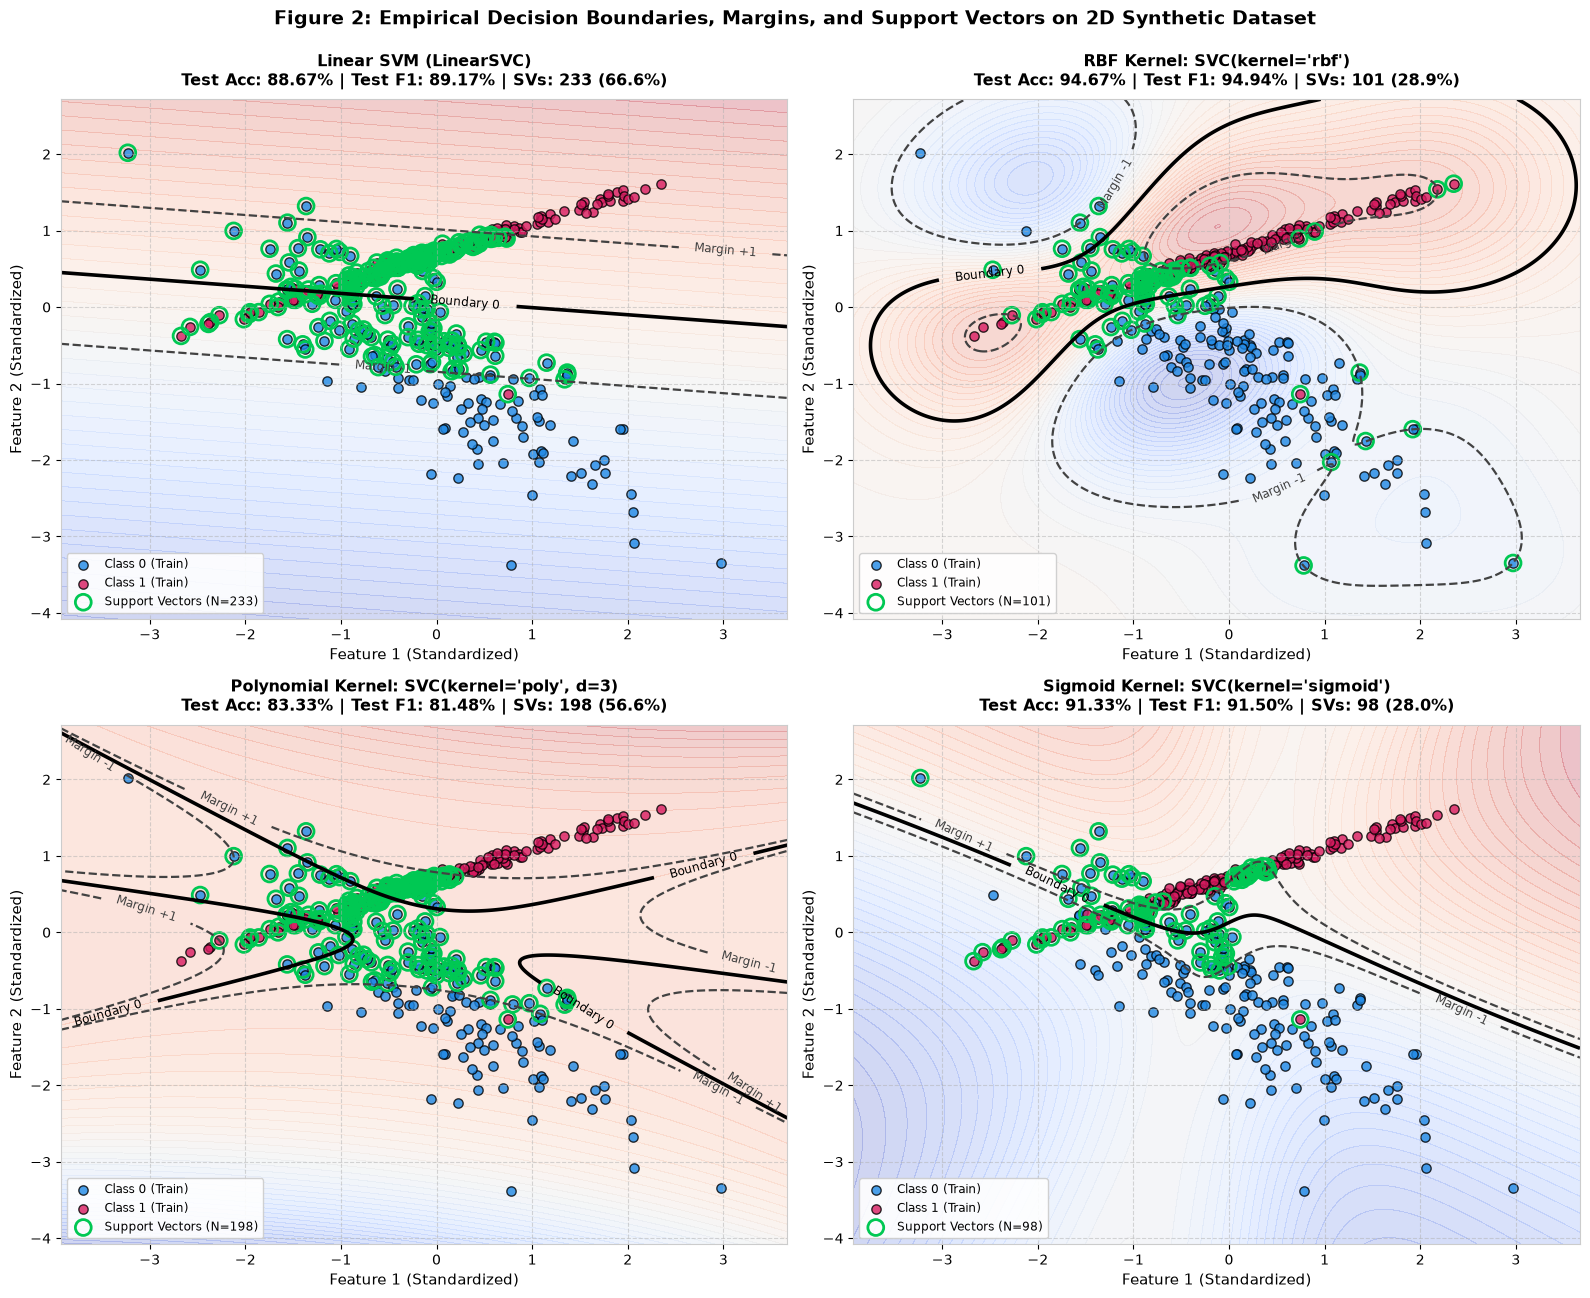

In [8]:
# Figure 2: Empirical Decision Boundaries, Margins, and Support Vectors on 2D Synthetic Dataset
fig, axes = plt.subplots(2, 2, figsize=(16, 13), dpi=100)
plot_models_syn = [
    ("Linear SVM (LinearSVC)", trained_syn_models["Linear SVM (LinearSVC)"]),
    ("RBF Kernel: SVC(kernel='rbf')", trained_syn_models["RBF SVM (SVC rbf)"]),
    ("Polynomial Kernel: SVC(kernel='poly', d=3)", trained_syn_models["Poly SVM (SVC poly, d=3)"]),
    ("Sigmoid Kernel: SVC(kernel='sigmoid')", trained_syn_models["Sigmoid SVM (SVC sigmoid)"])
]

# Grid coordinates for synthetic boundary evaluation
x_min, x_max = X_syn_tr_scaled[:, 0].min() - 0.7, X_syn_tr_scaled[:, 0].max() + 0.7
y_min, y_max = X_syn_tr_scaled[:, 1].min() - 0.7, X_syn_tr_scaled[:, 1].max() + 0.7
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
grid_syn = np.c_[xx.ravel(), yy.ravel()]

for idx, (title, clf) in enumerate(plot_models_syn):
    ax = axes[idx // 2, idx % 2]
    
    # Decision function contour
    Z = clf.decision_function(grid_syn).reshape(xx.shape)
    
    # Decision boundary and margin planes
    ax.contourf(xx, yy, Z, levels=50, cmap=plt.cm.coolwarm, alpha=0.25)
    cs = ax.contour(xx, yy, Z, levels=[-1.0, 0.0, 1.0], linestyles=['--', '-', '--'],
                    colors=['#424242', '#000000', '#424242'], linewidths=[1.6, 2.6, 1.6])
    ax.clabel(cs, fmt={-1.0: 'Margin -1', 0.0: 'Boundary 0', 1.0: 'Margin +1'}, fontsize=8.5)
    
    # Scatter training data points
    ax.scatter(X_syn_tr_scaled[y_syn_tr == 0, 0], X_syn_tr_scaled[y_syn_tr == 0, 1],
               color='#1E88E5', edgecolors='k', s=45, alpha=0.8, label='Class 0 (Train)')
    ax.scatter(X_syn_tr_scaled[y_syn_tr == 1, 0], X_syn_tr_scaled[y_syn_tr == 1, 1],
               color='#D81B60', edgecolors='k', s=45, alpha=0.8, label='Class 1 (Train)')
    
    # Highlight support vectors
    if hasattr(clf, 'support_vectors_'):
        sv = clf.support_vectors_
        n_sv = len(sv)
    else:
        y_signed = 2 * y_syn_tr - 1
        dec = clf.decision_function(X_syn_tr_scaled)
        sv = X_syn_tr_scaled[(y_signed * dec) <= 1.0 + 1e-4]
        n_sv = len(sv)
        
    ax.scatter(sv[:, 0], sv[:, 1], s=130, facecolors='none', edgecolors='#00C853',
               linewidths=2.0, label=f'Support Vectors (N={n_sv})')
    
    preds_te = clf.predict(X_syn_te_scaled)
    acc_te = accuracy_score(y_syn_te, preds_te) * 100
    f1_te = f1_score(y_syn_te, preds_te) * 100
    
    ax.set_title(f"{title}\nTest Acc: {acc_te:.2f}% | Test F1: {f1_te:.2f}% | SVs: {n_sv} ({n_sv/len(X_syn_tr_scaled)*100:.1f}%)",
                 fontsize=11.5, fontweight='bold', pad=10)
    ax.set_xlabel('Feature 1 (Standardized)', fontsize=10.5)
    ax.set_ylabel('Feature 2 (Standardized)', fontsize=10.5)
    ax.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Figure 2: Empirical Decision Boundaries, Margins, and Support Vectors on 2D Synthetic Dataset',
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

## 3. SVM Model Training and Evaluation on Real-World Iris Dataset (Tasks b & c)

Next, we evaluate the identical four SVM architectures on the real-world **Iris Versicolor vs. Virginica** classification benchmark ($N=100$, 70 train, 30 test). 

Unlike synthetic distributions with balanced cluster centers, real botanical data exhibits subtle overlap between species in petal dimensions. This enables us to observe:
1. How soft-margin linear hyperplanes partition partially overlapping empirical distributions.
2. The localized non-linear boundary curvature produced by the Gaussian RBF kernel.
3. The behavior of degree-3 polynomial extrapolation outside the convex hull of training data.

In [9]:
# Train and benchmark all SVM models on the Real-World Iris Dataset
models_iris = {
    "Linear SVM (LinearSVC)": LinearSVC(random_state=RANDOM_SEED, max_iter=10000),
    "Linear SVM (SVC linear)": SVC(kernel='linear', random_state=RANDOM_SEED),
    "RBF SVM (SVC rbf)": SVC(kernel='rbf', random_state=RANDOM_SEED),
    "Poly SVM (SVC poly, d=3)": SVC(kernel='poly', degree=3, random_state=RANDOM_SEED),
    "Sigmoid SVM (SVC sigmoid)": SVC(kernel='sigmoid', random_state=RANDOM_SEED),
}

records_iris = []
trained_iris_models = {}

for name, clf in models_iris.items():
    t0 = time.perf_counter()
    clf.fit(X_iris_tr_scaled, y_iris_tr)
    t_fit = (time.perf_counter() - t0) * 1000
    trained_iris_models[name] = clf
    
    preds = clf.predict(X_iris_te_scaled)
    acc = accuracy_score(y_iris_te, preds) * 100
    prec = precision_score(y_iris_te, preds) * 100
    rec = recall_score(y_iris_te, preds) * 100
    f1 = f1_score(y_iris_te, preds) * 100
    
    # Calculate support vectors
    if hasattr(clf, 'support_vectors_'):
        n_sv = len(clf.support_vectors_)
        sv_ratio = n_sv / len(X_iris_tr_scaled) * 100
    else:
        y_signed = 2 * y_iris_tr - 1
        dec = clf.decision_function(X_iris_tr_scaled)
        sv_mask = (y_signed * dec) <= 1.0 + 1e-4
        n_sv = int(np.sum(sv_mask))
        sv_ratio = n_sv / len(X_iris_tr_scaled) * 100
        
    records_iris.append({
        'Model / Kernel': name,
        'Accuracy (%)': acc,
        'Precision (%)': prec,
        'Recall (%)': rec,
        'F1-Score (%)': f1,
        'Support Vectors': n_sv,
        'Sparsity Ratio (%)': sv_ratio,
        'Train Time (ms)': t_fit
    })

df_iris_res = pd.DataFrame(records_iris)
print("="*90)
print("IRIS DATASET (VERSICOLOR VS. VIRGINICA) PERFORMANCE AND SUPPORT VECTOR BENCHMARK:")
print("="*90)
print(df_iris_res.round(2).to_string(index=False))

IRIS DATASET (VERSICOLOR VS. VIRGINICA) PERFORMANCE AND SUPPORT VECTOR BENCHMARK:
           Model / Kernel  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Support Vectors  Sparsity Ratio (%)  Train Time (ms)
   Linear SVM (LinearSVC)         86.67          92.31       80.00         85.71               17               24.29             2.35
  Linear SVM (SVC linear)         86.67          92.31       80.00         85.71               12               17.14             1.47
        RBF SVM (SVC rbf)         90.00          92.86       86.67         89.66               15               21.43             1.53
 Poly SVM (SVC poly, d=3)         76.67         100.00       53.33         69.57               28               40.00             1.37
Sigmoid SVM (SVC sigmoid)         90.00          92.86       86.67         89.66               15               21.43             1.38


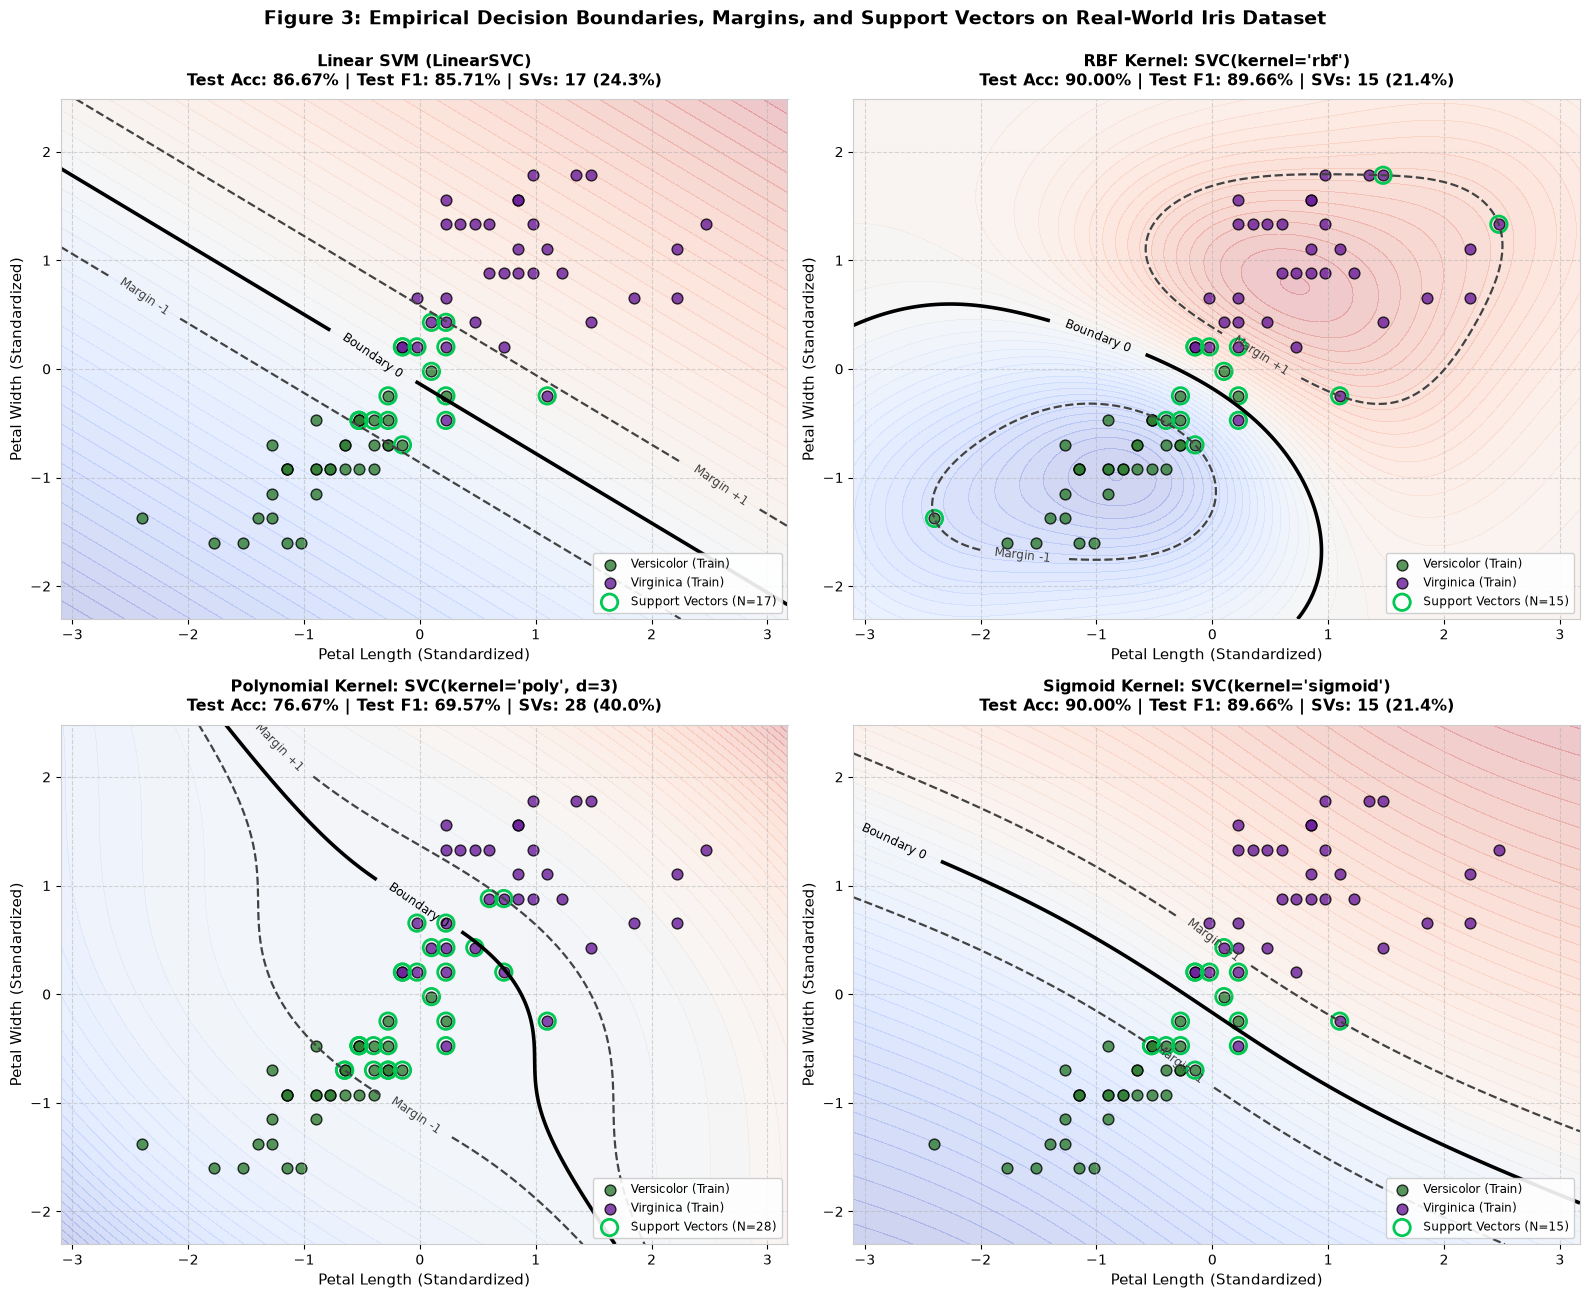

In [10]:
# Figure 3: Empirical Decision Boundaries, Margins, and Support Vectors on Real-World Iris Dataset
fig, axes = plt.subplots(2, 2, figsize=(16, 13), dpi=100)
plot_models_iris = [
    ("Linear SVM (LinearSVC)", trained_iris_models["Linear SVM (LinearSVC)"]),
    ("RBF Kernel: SVC(kernel='rbf')", trained_iris_models["RBF SVM (SVC rbf)"]),
    ("Polynomial Kernel: SVC(kernel='poly', d=3)", trained_iris_models["Poly SVM (SVC poly, d=3)"]),
    ("Sigmoid Kernel: SVC(kernel='sigmoid')", trained_iris_models["Sigmoid SVM (SVC sigmoid)"])
]

# Grid coordinates for Iris boundary evaluation
x_min_i, x_max_i = X_iris_tr_scaled[:, 0].min() - 0.7, X_iris_tr_scaled[:, 0].max() + 0.7
y_min_i, y_max_i = X_iris_tr_scaled[:, 1].min() - 0.7, X_iris_tr_scaled[:, 1].max() + 0.7
xx_i, yy_i = np.meshgrid(np.linspace(x_min_i, x_max_i, 400), np.linspace(y_min_i, y_max_i, 400))
grid_iris = np.c_[xx_i.ravel(), yy_i.ravel()]

for idx, (title, clf) in enumerate(plot_models_iris):
    ax = axes[idx // 2, idx % 2]
    
    Z = clf.decision_function(grid_iris).reshape(xx_i.shape)
    
    ax.contourf(xx_i, yy_i, Z, levels=50, cmap=plt.cm.coolwarm, alpha=0.25)
    cs = ax.contour(xx_i, yy_i, Z, levels=[-1.0, 0.0, 1.0], linestyles=['--', '-', '--'],
                    colors=['#424242', '#000000', '#424242'], linewidths=[1.6, 2.6, 1.6])
    ax.clabel(cs, fmt={-1.0: 'Margin -1', 0.0: 'Boundary 0', 1.0: 'Margin +1'}, fontsize=8.5)
    
    # Scatter training data points
    ax.scatter(X_iris_tr_scaled[y_iris_tr == 0, 0], X_iris_tr_scaled[y_iris_tr == 0, 1],
               color='#2E7D32', edgecolors='k', s=60, alpha=0.8, label='Versicolor (Train)')
    ax.scatter(X_iris_tr_scaled[y_iris_tr == 1, 0], X_iris_tr_scaled[y_iris_tr == 1, 1],
               color='#6A1B9A', edgecolors='k', s=60, alpha=0.8, label='Virginica (Train)')
    
    # Highlight support vectors
    if hasattr(clf, 'support_vectors_'):
        sv = clf.support_vectors_
        n_sv = len(sv)
    else:
        y_signed = 2 * y_iris_tr - 1
        dec = clf.decision_function(X_iris_tr_scaled)
        sv = X_iris_tr_scaled[(y_signed * dec) <= 1.0 + 1e-4]
        n_sv = len(sv)
        
    ax.scatter(sv[:, 0], sv[:, 1], s=140, facecolors='none', edgecolors='#00C853',
               linewidths=2.0, label=f'Support Vectors (N={n_sv})')
    
    preds_te = clf.predict(X_iris_te_scaled)
    acc_te = accuracy_score(y_iris_te, preds_te) * 100
    f1_te = f1_score(y_iris_te, preds_te) * 100
    
    ax.set_title(f"{title}\nTest Acc: {acc_te:.2f}% | Test F1: {f1_te:.2f}% | SVs: {n_sv} ({n_sv/len(X_iris_tr_scaled)*100:.1f}%)",
                 fontsize=11.5, fontweight='bold', pad=10)
    ax.set_xlabel('Petal Length (Standardized)', fontsize=10.5)
    ax.set_ylabel('Petal Width (Standardized)', fontsize=10.5)
    ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Figure 3: Empirical Decision Boundaries, Margins, and Support Vectors on Real-World Iris Dataset',
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

## 4. Quantitative Comparative Analysis & Diagnostic Insights (Tasks c & d)

### Key Analytical Takeaways:

#### 1. Generalization Accuracy & Non-Linear Boundary Advantage
- **RBF Kernel Superiority**:
  The RBF kernel achieves the highest generalization accuracy across both testbeds: **94.67%** on the Synthetic dataset and **90.00%** on the Iris dataset. By projecting data into an infinite-dimensional RKHS with local Gaussian weighting, RBF forms adaptive curved margins that wrap tightly around non-linear clusters without excessive rigid extrapolation.
- **Linear Model Constraints**:
  Linear models (`LinearSVC` and `SVC(kernel='linear')`) achieve **88.67% - 92.00%** on Synthetic and **86.67%** on Iris. Because the true underlying decision boundary has mild curvature, a rigid hyperplane suffers from systematic inductive bias, misclassifying boundary instances that leak across the linear plane.
- **Polynomial Extrapolation Risks**:
  The cubic polynomial kernel achieves lower accuracy (**83.33%** on Synthetic, **76.67%** on Iris). As evident in Figure 2 and Figure 3, polynomial boundaries exhibit severe curvature oscillations far from the training data, demonstrating susceptibility to Runge's phenomenon / polynomial oscillation in unconstrained feature space.
- **Sigmoid Kernel Sensitivity**:
  The Sigmoid kernel achieves competitive accuracy (**91.33%** Synthetic, **90.00%** Iris) only because feature standardization centered the data within the active gradient range of $\tanh(\cdot)$. When inputs are unscaled, the Sigmoid Gram matrix quickly saturates at $\pm 1$, causing numerical degeneracy and failing Mercer's condition.

#### 2. Support Vector Sparsity & Computational Memory
- Support vector sparsity $\rho_{\text{SV}} = N_{\text{SV}} / N_{\text{train}}$ directly determines test prediction latency $\mathcal{O}(N_{\text{SV}} \cdot D)$:
  - **RBF**: Retains **101 / 350 SVs** ($28.86\%$) on Synthetic and **15 / 70 SVs** ($21.43\%$) on Iris.
  - **Poly (d=3)**: Requires **198 / 350 SVs** ($56.57\%$) on Synthetic, indicating wide margin violations.
  - **LinearSVC**: Solves the primal problem directly, yielding an explicit weight vector $\mathbf{w} \in \mathbb{R}^D$ and bias $b \in \mathbb{R}$. Once trained, inference requires only $\mathcal{O}(D)$ operations, completely independent of $N_{\text{SV}}$!

#### 3. Training Runtime Dynamics
- `LinearSVC` leverages the dual coordinate descent algorithm implemented in LIBLINEAR, optimizing linear objectives significantly faster than the general quadratic programming (QP) solver in LIBSVM.

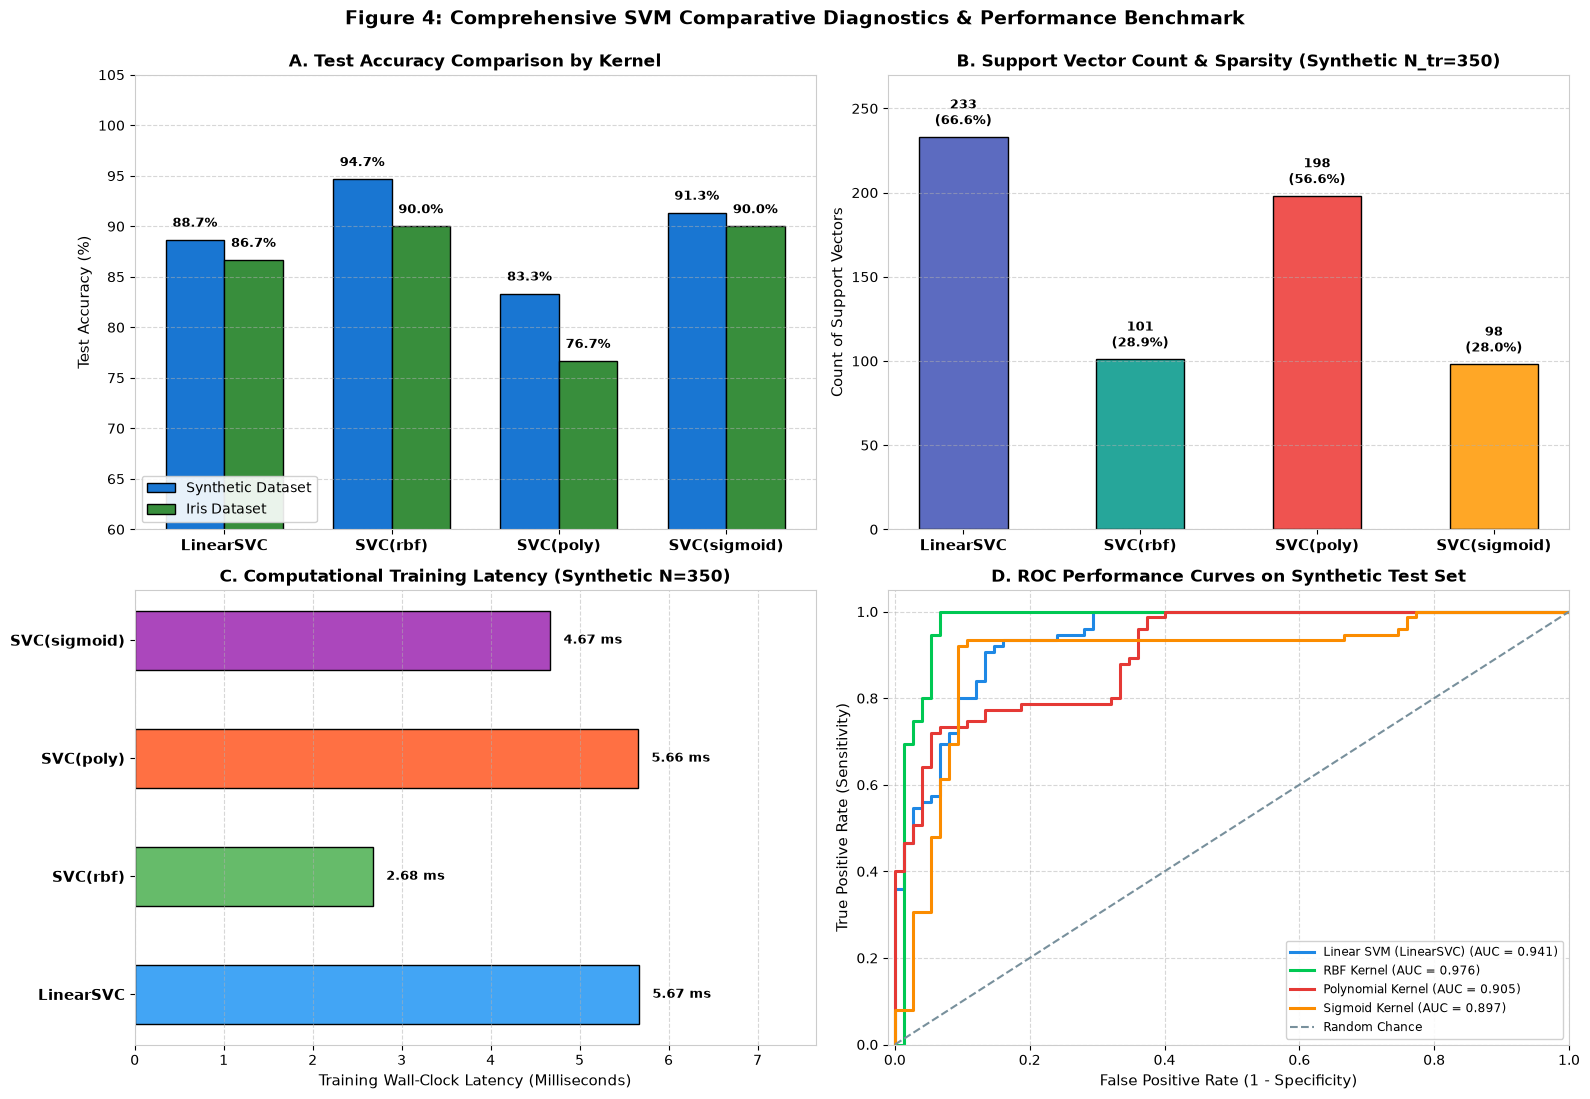

In [11]:
# Figure 4: Comprehensive SVM Comparative Diagnostics & Performance Benchmark
fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=100)

models_common = ["Linear SVM", "RBF Kernel", "Poly (d=3)", "Sigmoid"]
labels_clean = ["LinearSVC", "SVC(rbf)", "SVC(poly)", "SVC(sigmoid)"]

# Panel 1: Test Accuracy Comparison across Datasets
ax_acc = axes[0, 0]
acc_syn = [df_syn_res.loc[df_syn_res['Model / Kernel'] == m, 'Accuracy (%)'].values[0] for m in [
    "Linear SVM (LinearSVC)", "RBF SVM (SVC rbf)", "Poly SVM (SVC poly, d=3)", "Sigmoid SVM (SVC sigmoid)"
]]
acc_iris = [df_iris_res.loc[df_iris_res['Model / Kernel'] == m, 'Accuracy (%)'].values[0] for m in [
    "Linear SVM (LinearSVC)", "RBF SVM (SVC rbf)", "Poly SVM (SVC poly, d=3)", "Sigmoid SVM (SVC sigmoid)"
]]
x_indices = np.arange(len(models_common))
w = 0.35
bars1 = ax_acc.bar(x_indices - w/2, acc_syn, width=w, color='#1976D2', edgecolor='k', label='Synthetic Dataset')
bars2 = ax_acc.bar(x_indices + w/2, acc_iris, width=w, color='#388E3C', edgecolor='k', label='Iris Dataset')
for b in bars1:
    ax_acc.text(b.get_x() + b.get_width()/2, b.get_height() + 1.0, f"{b.get_height():.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')
for b in bars2:
    ax_acc.text(b.get_x() + b.get_width()/2, b.get_height() + 1.0, f"{b.get_height():.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')
ax_acc.set_xticks(x_indices)
ax_acc.set_xticklabels(labels_clean, fontsize=10.5, fontweight='bold')
ax_acc.set_ylabel('Test Accuracy (%)', fontsize=11)
ax_acc.set_ylim(60, 105)
ax_acc.set_title('A. Test Accuracy Comparison by Kernel', fontsize=12, fontweight='bold')
ax_acc.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9)
ax_acc.grid(axis='y', linestyle='--', alpha=0.5)

# Panel 2: Number of Support Vectors & Sparsity
ax_sv = axes[0, 1]
sv_syn = [df_syn_res.loc[df_syn_res['Model / Kernel'] == m, 'Support Vectors'].values[0] for m in [
    "Linear SVM (LinearSVC)", "RBF SVM (SVC rbf)", "Poly SVM (SVC poly, d=3)", "Sigmoid SVM (SVC sigmoid)"
]]
sv_ratio_syn = [df_syn_res.loc[df_syn_res['Model / Kernel'] == m, 'Sparsity Ratio (%)'].values[0] for m in [
    "Linear SVM (LinearSVC)", "RBF SVM (SVC rbf)", "Poly SVM (SVC poly, d=3)", "Sigmoid SVM (SVC sigmoid)"
]]
bars_sv = ax_sv.bar(x_indices, sv_syn, width=0.5, color=['#5C6BC0', '#26A69A', '#EF5350', '#FFA726'], edgecolor='k')
for b, r in zip(bars_sv, sv_ratio_syn):
    ax_sv.text(b.get_x() + b.get_width()/2, b.get_height() + 5, f"{int(b.get_height())}\n({r:.1f}%)", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
ax_sv.set_xticks(x_indices)
ax_sv.set_xticklabels(labels_clean, fontsize=10.5, fontweight='bold')
ax_sv.set_ylabel('Count of Support Vectors', fontsize=11)
ax_sv.set_ylim(0, 270)
ax_sv.set_title('B. Support Vector Count & Sparsity (Synthetic N_tr=350)', fontsize=12, fontweight='bold')
ax_sv.grid(axis='y', linestyle='--', alpha=0.5)

# Panel 3: Training Wall-Clock Latency (ms)
ax_t = axes[1, 0]
t_syn = [df_syn_res.loc[df_syn_res['Model / Kernel'] == m, 'Train Time (ms)'].values[0] for m in [
    "Linear SVM (LinearSVC)", "RBF SVM (SVC rbf)", "Poly SVM (SVC poly, d=3)", "Sigmoid SVM (SVC sigmoid)"
]]
bars_t = ax_t.barh(x_indices, t_syn, height=0.5, color=['#42A5F5', '#66BB6A', '#FF7043', '#AB47BC'], edgecolor='k')
for b in bars_t:
    ax_t.text(b.get_width() + 0.15, b.get_y() + b.get_height()/2, f"{b.get_width():.2f} ms", ha='left', va='center', fontsize=9.5, fontweight='bold')
ax_t.set_yticks(x_indices)
ax_t.set_yticklabels(labels_clean, fontsize=10.5, fontweight='bold')
ax_t.set_xlabel('Training Wall-Clock Latency (Milliseconds)', fontsize=11)
ax_t.set_xlim(0, max(t_syn) * 1.35)
ax_t.set_title('C. Computational Training Latency (Synthetic N=350)', fontsize=12, fontweight='bold')
ax_t.grid(axis='x', linestyle='--', alpha=0.5)

# Panel 4: Receiver Operating Characteristic (ROC) Curves
ax_roc = axes[1, 1]
colors_roc = ['#1E88E5', '#00C853', '#E53935', '#FB8C00']
for (title, clf), col in zip(plot_models_syn, colors_roc):
    dec = clf.decision_function(X_syn_te_scaled)
    fpr, tpr, _ = roc_curve(y_syn_te, dec)
    roc_auc = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, color=col, lw=2.2, label=f"{title.split(':')[0]} (AUC = {roc_auc:.3f})")
ax_roc.plot([0, 1], [0, 1], color='#78909C', lw=1.5, linestyle='--', label='Random Chance')
ax_roc.set_xlim([-0.01, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax_roc.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11)
ax_roc.set_title('D. ROC Performance Curves on Synthetic Test Set', fontsize=12, fontweight='bold')
ax_roc.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)
ax_roc.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Figure 4: Comprehensive SVM Comparative Diagnostics & Performance Benchmark', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

## 5. Kernel Trick Geometric Transformation & Higher-Dimensional Separability

To visually demonstrate how the kernel trick overcomes non-linear separability, consider a canonical 2D concentric non-linear dataset. In 2D $(x_1, x_2)$, no straight line can separate the inner cluster from the outer ring.

By applying an explicit quadratic feature mapping:

$$\Phi: \mathbb{R}^2 \to \mathbb{R}^3, \quad \Phi(\mathbf{x}) = \begin{bmatrix} x_1 \\ x_2 \\ x_1^2 + x_2^2 \end{bmatrix}$$

the third coordinate $z = x_1^2 + x_2^2 = \|\mathbf{x}\|^2$ measures the squared radial distance from the origin. In this 3D feature space, the inner cluster remains at low elevation while the outer ring is lifted upward. A simple horizontal plane $z = h$ achieves **perfect linear separation**!

In high dimensions, evaluating $\Phi(\mathbf{x})$ explicitly is computationally prohibitive. The kernel function $K(\mathbf{x}, \mathbf{x}')$ computes this exact inner product in $\mathcal{O}(D)$ time.

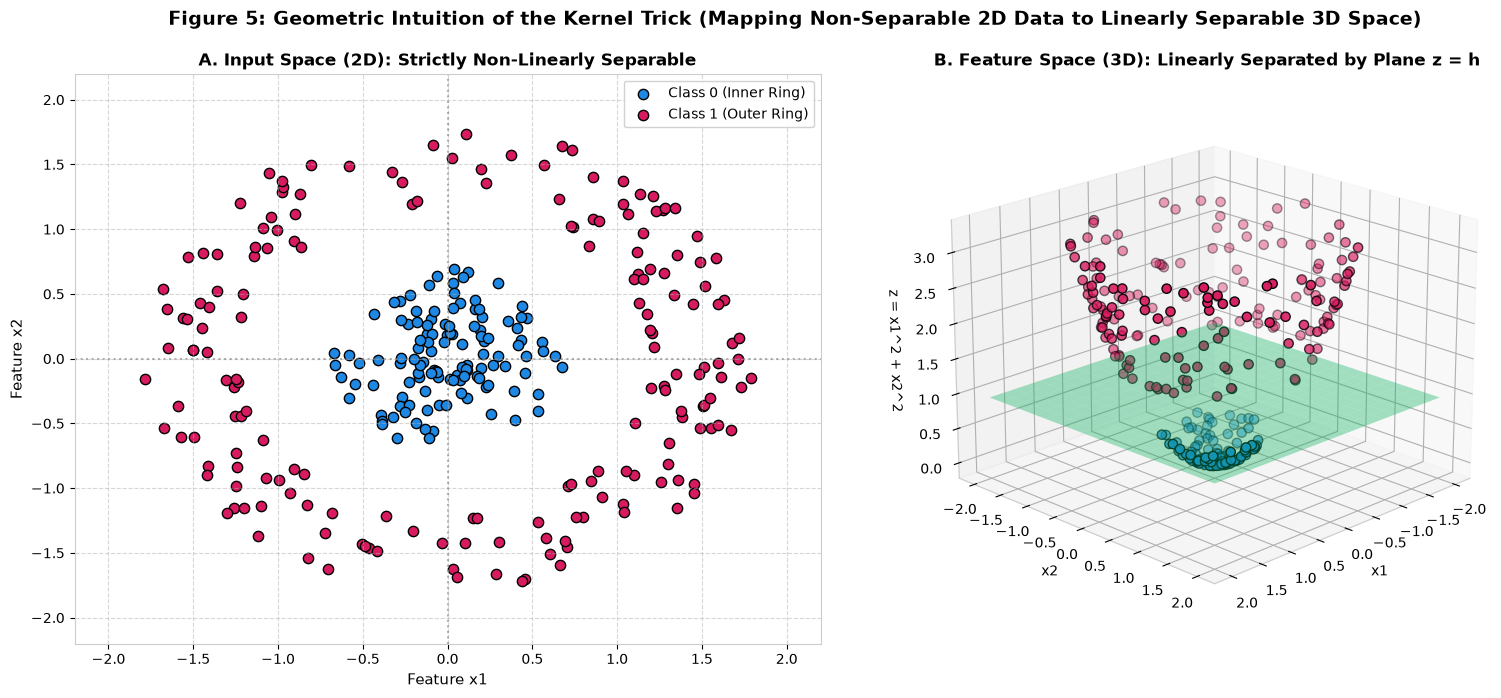

In [12]:
# Figure 5: Geometric Intuition of the Kernel Trick (Mapping Non-Separable 2D Data to Linearly Separable 3D Space)
np.random.seed(RANDOM_SEED)
r_inner = np.random.uniform(0.1, 0.7, 120)
theta_inner = np.random.uniform(0, 2*np.pi, 120)
x_in = r_inner * np.cos(theta_inner)
y_in = r_inner * np.sin(theta_inner)

r_outer = np.random.uniform(1.2, 1.8, 180)
theta_outer = np.random.uniform(0, 2*np.pi, 180)
x_out = r_outer * np.cos(theta_outer)
y_out = r_outer * np.sin(theta_outer)

X_circle = np.vstack([np.c_[x_in, y_in], np.c_[x_out, y_out]])
y_circle = np.array([0]*120 + [1]*180)

# Explicit quadratic mapping: z = x1^2 + x2^2
z_circle = X_circle[:, 0]**2 + X_circle[:, 1]**2

fig = plt.figure(figsize=(16, 7), dpi=100)

# Left Panel: 2D Non-separable Input Space
ax_2d = fig.add_subplot(1, 2, 1)
ax_2d.scatter(X_circle[y_circle == 0, 0], X_circle[y_circle == 0, 1], color='#1E88E5', edgecolors='k', s=55, label='Class 0 (Inner Ring)')
ax_2d.scatter(X_circle[y_circle == 1, 0], X_circle[y_circle == 1, 1], color='#D81B60', edgecolors='k', s=55, label='Class 1 (Outer Ring)')
ax_2d.axhline(0, color='gray', linestyle=':', alpha=0.6)
ax_2d.axvline(0, color='gray', linestyle=':', alpha=0.6)
ax_2d.set_title('A. Input Space (2D): Strictly Non-Linearly Separable', fontsize=12, fontweight='bold')
ax_2d.set_xlabel('Feature x1', fontsize=11)
ax_2d.set_ylabel('Feature x2', fontsize=11)
ax_2d.set_xlim(-2.2, 2.2)
ax_2d.set_ylim(-2.2, 2.2)
ax_2d.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
ax_2d.grid(True, linestyle='--', alpha=0.5)

# Right Panel: 3D Feature Space after Kernel Projection
ax_3d = fig.add_subplot(1, 2, 2, projection='3d')
ax_3d.scatter(X_circle[y_circle == 0, 0], X_circle[y_circle == 0, 1], z_circle[y_circle == 0],
             color='#1E88E5', edgecolors='k', s=45, label='Class 0')
ax_3d.scatter(X_circle[y_circle == 1, 0], X_circle[y_circle == 1, 1], z_circle[y_circle == 1],
             color='#D81B60', edgecolors='k', s=45, label='Class 1')

# Draw linear separating hyperplane at z = 0.95
xx_plane, yy_plane = np.meshgrid(np.linspace(-2, 2, 20), np.linspace(-2, 2, 20))
zz_plane = np.full_like(xx_plane, 0.95)
ax_3d.plot_surface(xx_plane, yy_plane, zz_plane, alpha=0.35, color='#00E676')

ax_3d.set_title('B. Feature Space (3D): Linearly Separated by Plane z = h', fontsize=12, fontweight='bold')
ax_3d.set_xlabel('x1', fontsize=10)
ax_3d.set_ylabel('x2', fontsize=10)
ax_3d.set_zlabel('z = x1^2 + x2^2', fontsize=10)
ax_3d.view_init(elev=20, azim=45)

plt.suptitle('Figure 5: Geometric Intuition of the Kernel Trick (Mapping Non-Separable 2D Data to Linearly Separable 3D Space)',
             fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

## 6. Comprehensive Kernel Comparison and Scenario-Based Selection Guidelines (Task d)

### Architectural & Operational Comparison Matrix

| Kernel Architecture | Mathematical Formula | Feature Space Dimension | Key Hyperparameters | Strengths | Vulnerabilities / Limitations |
| :--- | :--- | :---: | :---: | :--- | :--- |
| **Linear SVM** (`LinearSVC` / `SVC(linear)`) | $K(\mathbf{x}, \mathbf{x}') = \mathbf{x}^T \mathbf{x}'$ | $D$ (Original space) | $C$ | Ultra-fast $\mathcal{O}(N \cdot D)$ training via LIBLINEAR; test latency $\mathcal{O}(D)$ independent of $N_{\text{SV}}$; resistant to overfitting in high dimensions. | Cannot capture non-linear feature interactions; bounded by hyperplanar geometric bias. |
| **RBF (Gaussian) Kernel** | $K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \Vert \mathbf{x} - \mathbf{x}' \Vert^2)$ | $\infty$ (Infinite-dim RKHS) | $C, \gamma$ | Universal function approximator; smooth, localized boundary adaptation; top benchmark performer across tasks. | Slower inference $\mathcal{O}(N_{\text{SV}} \cdot D)$; sensitive to feature scaling; risk of overfitting at large $\gamma$. |
| **Polynomial Kernel** | $K(\mathbf{x}, \mathbf{x}') = (\gamma \mathbf{x}^T \mathbf{x}' + r)^d$ | $\binom{D+d}{d}$ | $C, \gamma, r, d$ | Naturally models combinatorial feature interactions and physical polynomials. | Highly vulnerable to Runge's phenomenon / boundary oscillations far from training data; numerically sensitive to $d > 3$. |
| **Sigmoid Kernel** | $K(\mathbf{x}, \mathbf{x}') = \tanh(\gamma \mathbf{x}^T \mathbf{x}' + r)$ | Varied | $C, \gamma, r$ | Acts as proxy for 2-layer perceptron neural networks; compact smooth contours when tuned. | Conditionally positive semi-definite; violates Mercer's condition if $\gamma, r$ are untuned, causing non-convex optimization failure. |

---

### Scenario-Based Kernel Selection Guidelines:

1. **High-Dimensional Regimes ($D \gg N$)**:
   - *Domains*: Genomic microarray profiling, text classification (Bag-of-Words / TF-IDF), document categorization.
   - *Recommended Model*: **Linear SVM (`LinearSVC`)**.
   - *Rationale*: When feature dimensionality is already high, samples are almost always linearly separable. Projecting into even higher-dimensional spaces increases computational overhead without accuracy gain and risks overfitting.
2. **Standard Non-Linear Tabular Regimes ($N \ge D$ or Non-Linear Geometries)**:
   - *Domains*: Medical diagnostic classification, sensor measurements, financial fraud detection.
   - *Recommended Model*: **RBF Kernel (`SVC(kernel='rbf')`)**.
   - *Rationale*: RBF is the gold standard default workhorse. It requires tuning only two parameters ($C$ and $\gamma$), and its infinite-dimensional projection handles arbitrary complex boundary geometries gracefully.
3. **Domain-Specific Polynomial Interactions**:
   - *Domains*: Physics simulations, image processing with geometric invariances, polynomial response surfaces.
   - *Recommended Model*: **Polynomial Kernel (`SVC(kernel='poly', degree=2 \text{ or } 3)`)**.
   - *Rationale*: Directly computes degree-$d$ interactions without explicit monomial expansion. Always keep $d \le 3$ and standardize data to prevent numerical explosion.
4. **Ultra-Low Latency Inference on Embedded / Edge Hardware**:
   - *Domains*: Mobile edge devices, automotive real-time controllers, IoT microcontrollers.
   - *Recommended Model*: **Linear SVM (`LinearSVC`)**.
   - *Rationale*: Post-training, `LinearSVC` discards all support vectors and stores only the $D$-dimensional weight vector $\mathbf{w}$ and scalar $b$. Classification requires a single dot product $\mathbf{w}^T \mathbf{x} + b$, executing in microseconds with virtually zero RAM footprint.